# Rebuttal analysis: Plot all responses from F3

## imports

In [46]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
#import json
#import navis
#import seaborn as sns
from pathlib import Path
from eyewire2_functional_analysis.skeleton import rotate_skel
import skeliner as sk
from eyewire2_functional_analysis import data_loader
#from eyewire2_functional_analysis import plot
#import plot

## helper functions

In [47]:
def plot_swc(df, ax=None, color="darkred", lw=0.8):
    """
    Plot a 2D SWC morphology.
    """

    if ax is None:
        fig, ax = plt.subplots(figsize=(4, 4))

    nodes = df.set_index("id")

    # Draw branches
    for _, row in df.iterrows():
        if row.parent == -1:
            continue

        parent = nodes.loc[row.parent]

        ax.plot(
            [parent.x, row.x],
            [parent.y, row.y],
            color=color,
            lw=lw,
            solid_capstyle="round",
        )

    # Soma
    soma = df.loc[df.parent == -1].iloc[0]
    ax.scatter(soma.x, soma.y, s=20, color="k", zorder=10)

    # Tight limits
    pad = 2
    ax.set_xlim(df.x.min() - pad, df.x.max() + pad)
    ax.set_ylim(df.y.min() - pad, df.y.max() + pad)

    ax.set_aspect("equal", adjustable="box")
    ax.set_anchor("W")          # <-- removes whitespace on the left
    ax.margins(0)

    ax.axis("off")

    return ax

def add_skels(df):
    df = df.copy()
    df['swc_path'] = df['Latest SegID'].apply(lambda x: os.path.join(skel_dir, f"{x}.swc"))
    df['skel'] = df.apply(lambda row: sk.io.load_swc(row['swc_path']) if os.path.isfile(row['swc_path']) else None, axis=1)
    return df


def plot_cells(df, figsize=None, fontsize_factor=1, row_gap=0.5):
    n_rows = len(df)

    if n_rows == 0:
        raise ValueError("The DataFrame contains no cells to plot.")

    if figsize is None:
        figsize = (8, n_rows * 1.2)

    # Gaps add to the figure height, so the height of each cell row stays fixed
    cell_height = figsize[1] / n_rows
    gap_height = cell_height * row_gap / (0.22 + 1.0)
    figsize = (figsize[0], figsize[1] + (n_rows - 1) * gap_height)

    fig = plt.figure(figsize=figsize, layout="constrained")

    gs = fig.add_gridspec(
        nrows=3 * n_rows - 1,
        ncols=5,
        # More space for the morphology column
        width_ratios=(1.5, 0.5, 1.6, 1.6, 0.6),
        # Each cell: header, content, then an empty spacer row (except after the last)
        height_ratios=([0.22, 1.0, row_gap] * n_rows)[:-1],
    )

    axs = np.empty((n_rows, 5), dtype=object)

    for i, (_, row) in enumerate(df.iterrows()):
        # ------------------------------------------------------------
        # Full-width ROI header
        # ------------------------------------------------------------
        header_ax = fig.add_subplot(gs[3 * i, :])
        header_ax.axis("off")

        label = (
            f"ROI: {row['roi_id']}, " 
            f"{row['Cell Type']}\n"
            rf"$QI_{{\mathrm{{chirp}}}}$: {row['chirp_qidx']:.2f}, "
            rf"$QI_{{\mathrm{{bar}}}}$: {row['bar_qidx']:.2f}"
        )

        text = header_ax.text(
            0, 0.5, label,
            transform=header_ax.transAxes,
            ha="left",
            va="center",
            fontsize=8,
        )
        text.set_in_layout(False)

        for j in range(5):
            axs[i, j] = fig.add_subplot(
                gs[3 * i + 1, j],
                projection="polar" if j == 4 else None,
            )

        # ------------------------------------------------------------
        # Morphology
        # ------------------------------------------------------------
        ax = axs[i, 0]

        skel_rot = rotate_skel(row["skel"], rotation_deg=150)
        soma_center = np.asarray(skel_rot.soma.center).copy()
        skel_rot.nodes -= soma_center

        nodes = skel_rot.nodes[skel_rot.ntype == 3]
        if len(nodes) == 0:
            nodes = skel_rot.nodes

        # plane="yx": horizontal coordinate is y, vertical is x.
        # Include the soma when calculating the bounds.
        coords = np.vstack((nodes[:, [1, 0]], [[0.0, 0.0]]))
        lower = coords.min(axis=0)
        upper = coords.max(axis=0)

        extent = max(np.max(upper - lower), 1.0)

        # Extra space on the left for the scale bar
        xlim = (
            lower[0] - 0.25 * extent,
            upper[0] + 0.08 * extent,
        )
        ylim = (
            lower[1] - 0.08 * extent,
            upper[1] + 0.08 * extent,
        )

        sk.plot.projection(
            skel_rot,
            ax=ax,
            xlim=xlim,
            ylim=ylim,
            plane="yx",
            draw_cylinders=False,
        )

        # Explicitly enforce the per-cell limits after plotting
        ax.set_xlim(xlim)
        ax.set_ylim(ylim)
        ax.set_aspect("equal", adjustable="box")

        # Adaptive, labelled vertical scale bar
        yspan = ylim[1] - ylim[0]
        target = 0.25 * yspan
        magnitude = 10 ** np.floor(np.log10(target))
        candidates = magnitude * np.array([1, 2, 5])
        bar_size = candidates[candidates <= target].max()
        bar_fraction = bar_size / yspan

        ax.plot(
            [-0.10, -0.10],
            [0.08, 0.08 + bar_fraction],
            transform=ax.transAxes,
            color="k",
            lw=0.8,
            clip_on=False,
        )
        ax.text(
            -0.08,
            0.08 + bar_fraction / 2,
            f"{bar_size:g} µm",
            transform=ax.transAxes,
            rotation=90,
            ha="left",
            va="center",
            fontsize=6,
        )

        ax.set_rasterized(True)

        # ------------------------------------------------------------
        # IPL profile
        # ------------------------------------------------------------
        plot.plot_ipl_profile(ax=axs[i, 1], row=row)

        # ------------------------------------------------------------
        # Chirp response
        # ------------------------------------------------------------
        plot.plot_chirp(ax=axs[i, 2], row=row)

        # ------------------------------------------------------------
        # Moving-bar response
        # ------------------------------------------------------------
        plot.plot_bar(
            ax=axs[i, 3],
            row=row,
            annotate_dirs=False,
            annotate_symbols=i == 0,
            ventral_up=False,
        )

        for j in (2, 3):
            ax = axs[i, j]

            if i == n_rows - 1:
                plot.plot_scale_bar(
                    ax=ax,
                    x0=1,
                    y0=-0.4,
                    size=2,
                    text=True,
                    tdist=0.05,
                    unit="s",
                )

            ax.set_ylim(-0.5, 1.1)

        # ------------------------------------------------------------
        # Direction tuning
        # ------------------------------------------------------------
        plot.plot_bar_dir(
            ax=axs[i, 4],
            row=row,
            ventral_up=False,
        )

    for ax in axs[:, :-1].flat:
        ax.set(xlabel=None, ylabel=None, xticks=[], yticks=[])
        ax.axis("off")
        ax.set_facecolor((1, 1, 1, 0))

        
    from matplotlib.text import Text
    
        # Double every text object's current font size
    for text in fig.findobj(match=Text):
        text.set_fontsize(text.get_fontsize() * fontsize_factor)        
        
    return fig, axs

## load data

In [48]:
df_func_data = data_loader.load_df_rois_morph()

In [49]:
swc_dir = Path(r"C:\\Users\\teuler\Documents\\git\\huggingface\eyewire2-data\\swc_2p")
skel_dir = "C:\\Users\\teuler\\Documents\\git\\huggingface\\eyewire2-data\\swc_2p"

df_func_data['swc_path'] = ''
df_func_data['skel'] = None

swc_ids = {f.stem for f in swc_dir.glob("*.swc")}

# Check which spreadsheet IDs have a matching SWC
df_func_data["has_swc"] = df_func_data["Latest SegID"].isin(swc_ids)

print(f"Matched: {df_func_data['has_swc'].sum()} / {len(df_func_data)}")

Matched: 376 / 376


## select F3

In [50]:
df_type = add_skels(df_func_data)
df_func_f3 = df_type[df_type['2p-Field']=='GCL3']

C:\Users\teuler\AppData\Local\Temp\ipykernel_43736\4262754916.py:46: DeprecationWarning: load_swc() is deprecated, use load_skeleton_swc() instead.
  df['skel'] = df.apply(lambda row: sk.io.load_swc(row['swc_path']) if os.path.isfile(row['swc_path']) else None, axis=1)


## plotting

### test small subset

c:\Users\teuler\Documents\git\eyewire2-functional-analysis\.venv\Lib\site-packages\skeliner\plot\vis2d.py:656: UserWarning: Tight layout not applied. tight_layout cannot make Axes height small enough to accommodate all Axes decorations.
  plt.tight_layout()
c:\Users\teuler\Documents\git\eyewire2-functional-analysis\.venv\Lib\site-packages\skeliner\plot\vis2d.py:656: UserWarning: The figure layout has changed to tight
  plt.tight_layout()
c:\Users\teuler\Documents\git\eyewire2-functional-analysis\.venv\Lib\site-packages\skeliner\plot\vis2d.py:656: UserWarning: Tight layout not applied. tight_layout cannot make Axes height small enough to accommodate all Axes decorations.
  plt.tight_layout()


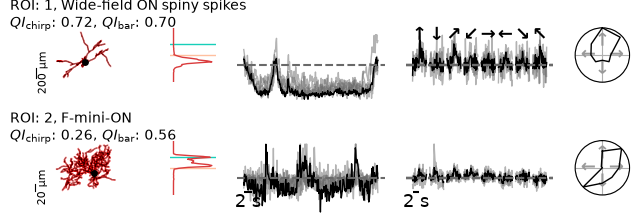

In [51]:
from eyewire2_functional_analysis import plot
fig, axs = plot_cells(df_func_f3.iloc[:2],
                     figsize=(8, 2),
                     fontsize_factor=1.3)
plt.show()

### plot 3 batches á 22 cells

In [52]:
from eyewire2_functional_analysis import plot
import matplotlib as mpl

fig_path = "C:\\Users\\teuler\\Documents\\git\\eyewire2-functional-analysis\\rebuttal_figs\\"

mpl.rcParams.update({
    "svg.fonttype": "none",
})

c:\Users\teuler\Documents\git\eyewire2-functional-analysis\.venv\Lib\site-packages\skeliner\plot\vis2d.py:656: UserWarning: Tight layout not applied. tight_layout cannot make Axes height small enough to accommodate all Axes decorations.
  plt.tight_layout()
c:\Users\teuler\Documents\git\eyewire2-functional-analysis\.venv\Lib\site-packages\skeliner\plot\vis2d.py:656: UserWarning: The figure layout has changed to tight
  plt.tight_layout()
c:\Users\teuler\Documents\git\eyewire2-functional-analysis\.venv\Lib\site-packages\skeliner\plot\vis2d.py:656: UserWarning: Tight layout not applied. tight_layout cannot make Axes height small enough to accommodate all Axes decorations.
  plt.tight_layout()
c:\Users\teuler\Documents\git\eyewire2-functional-analysis\.venv\Lib\site-packages\skeliner\plot\vis2d.py:656: UserWarning: Tight layout not applied. tight_layout cannot make Axes height small enough to accommodate all Axes decorations.
  plt.tight_layout()
c:\Users\teuler\Documents\git\eyewire2-fun

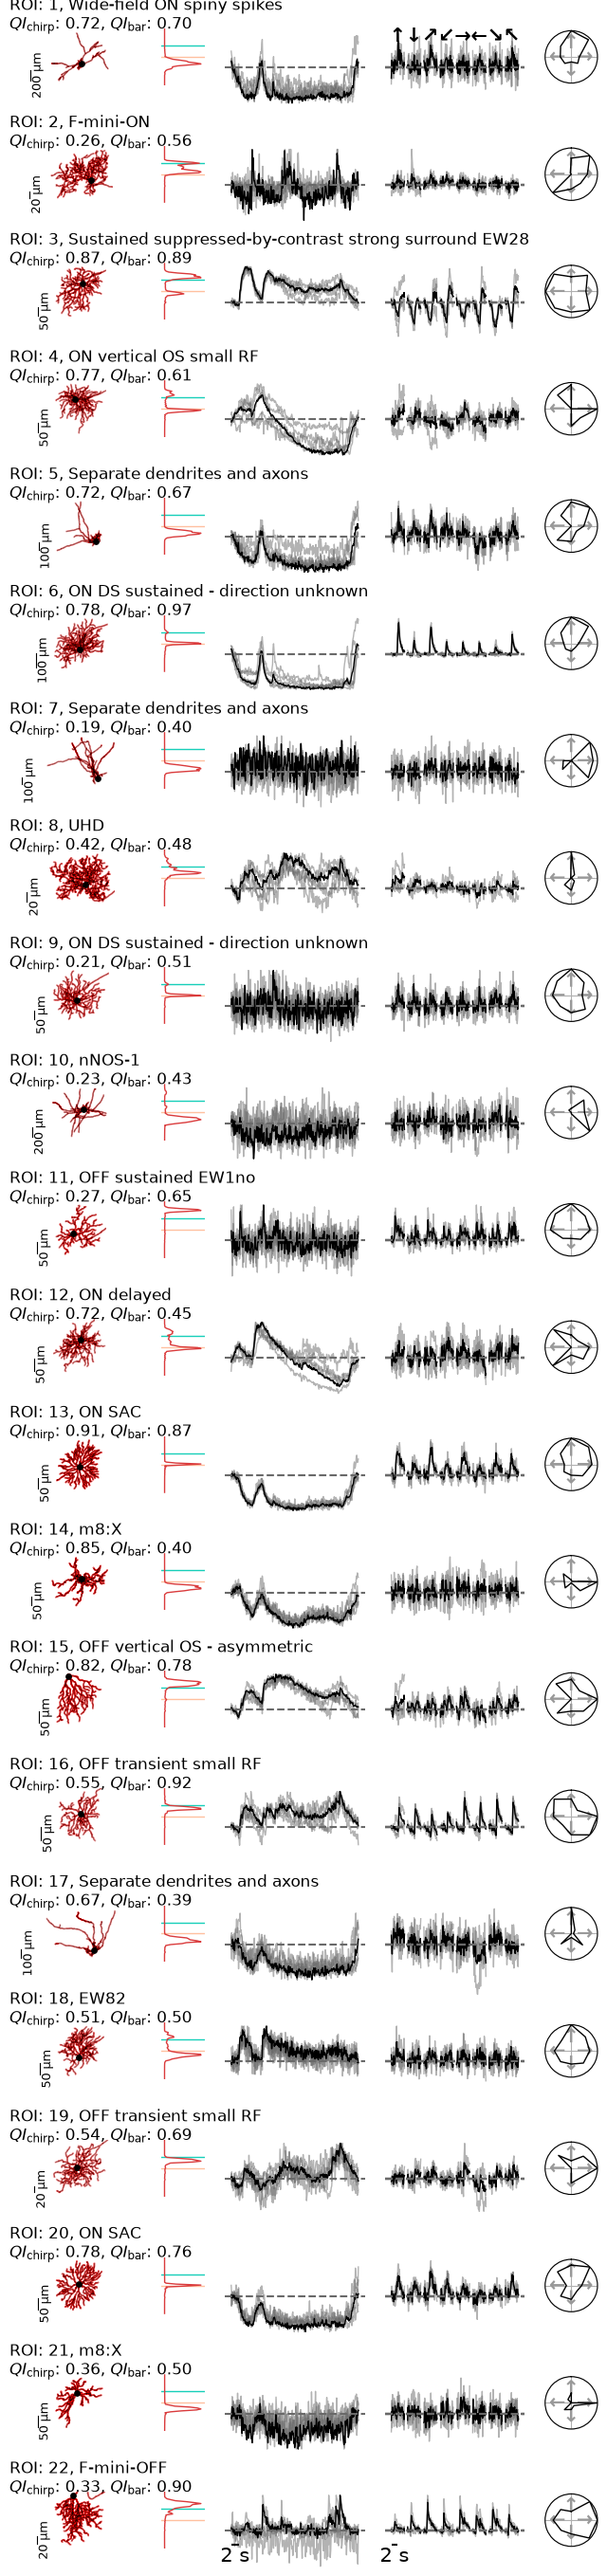

In [53]:
fig, axs = plot_cells(df_func_f3.iloc[:22],
                     figsize=(8, 25),
                     fontsize_factor=1.5)
plt.show()

figname = 'sFig_X_responses_F3_1-22'
fig.patch.set_facecolor('white')
fig.savefig(fig_path +"{}.png".format(figname), bbox_inches='tight', dpi=300, facecolor=fig.get_facecolor(), transparent=False)
fig.savefig(fig_path +"{}.svg".format(figname), bbox_inches='tight', dpi=300, facecolor=fig.get_facecolor(), transparent=False)

c:\Users\teuler\Documents\git\eyewire2-functional-analysis\.venv\Lib\site-packages\skeliner\plot\vis2d.py:656: UserWarning: Tight layout not applied. tight_layout cannot make Axes height small enough to accommodate all Axes decorations.
  plt.tight_layout()
c:\Users\teuler\Documents\git\eyewire2-functional-analysis\.venv\Lib\site-packages\skeliner\plot\vis2d.py:656: UserWarning: The figure layout has changed to tight
  plt.tight_layout()
c:\Users\teuler\Documents\git\eyewire2-functional-analysis\.venv\Lib\site-packages\skeliner\plot\vis2d.py:656: UserWarning: Tight layout not applied. tight_layout cannot make Axes height small enough to accommodate all Axes decorations.
  plt.tight_layout()
c:\Users\teuler\Documents\git\eyewire2-functional-analysis\.venv\Lib\site-packages\skeliner\plot\vis2d.py:656: UserWarning: Tight layout not applied. tight_layout cannot make Axes height small enough to accommodate all Axes decorations.
  plt.tight_layout()
c:\Users\teuler\Documents\git\eyewire2-fun

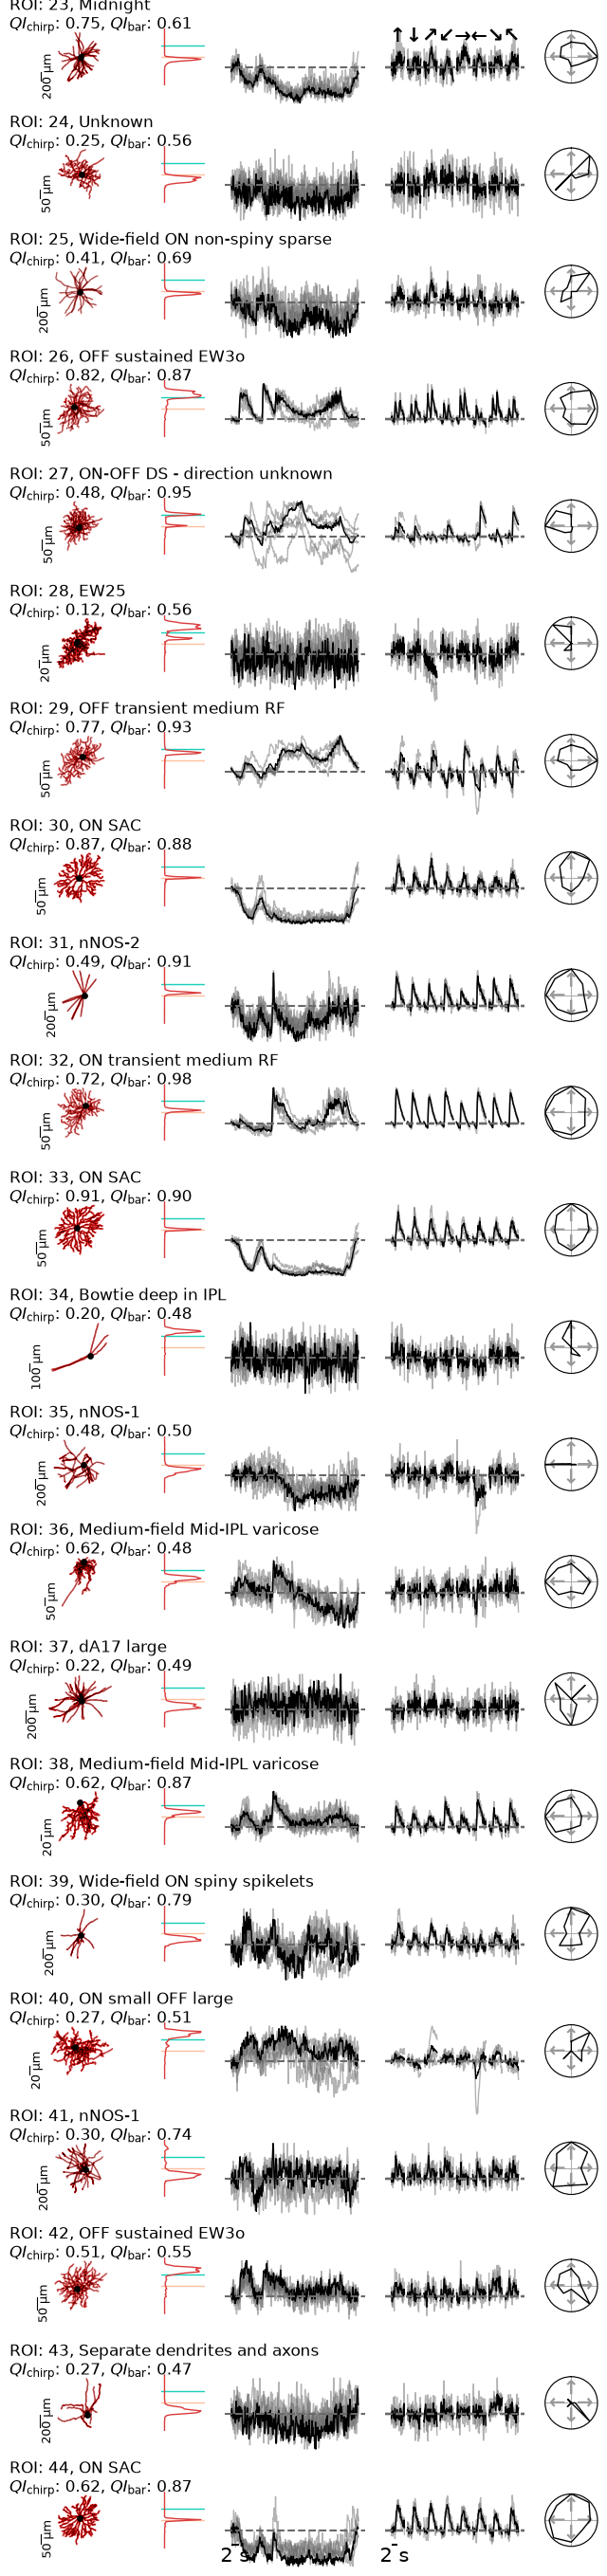

In [54]:
fig, axs = plot_cells(df_func_f3.iloc[22:44],
                     figsize=(8, 25),
                     fontsize_factor=1.5)
plt.show()

figname = 'sFig_X_responses_F3_23-44'
fig.patch.set_facecolor('white')
fig.savefig(fig_path +"{}.png".format(figname), bbox_inches='tight', dpi=300, facecolor=fig.get_facecolor(), transparent=False)
fig.savefig(fig_path +"{}.svg".format(figname), bbox_inches='tight', dpi=300, facecolor=fig.get_facecolor(), transparent=False)

c:\Users\teuler\Documents\git\eyewire2-functional-analysis\.venv\Lib\site-packages\skeliner\plot\vis2d.py:656: UserWarning: Tight layout not applied. tight_layout cannot make Axes height small enough to accommodate all Axes decorations.
  plt.tight_layout()
c:\Users\teuler\Documents\git\eyewire2-functional-analysis\.venv\Lib\site-packages\skeliner\plot\vis2d.py:656: UserWarning: The figure layout has changed to tight
  plt.tight_layout()
c:\Users\teuler\Documents\git\eyewire2-functional-analysis\.venv\Lib\site-packages\skeliner\plot\vis2d.py:656: UserWarning: Tight layout not applied. tight_layout cannot make Axes height small enough to accommodate all Axes decorations.
  plt.tight_layout()
c:\Users\teuler\Documents\git\eyewire2-functional-analysis\.venv\Lib\site-packages\skeliner\plot\vis2d.py:656: UserWarning: Tight layout not applied. tight_layout cannot make Axes height small enough to accommodate all Axes decorations.
  plt.tight_layout()
c:\Users\teuler\Documents\git\eyewire2-fun

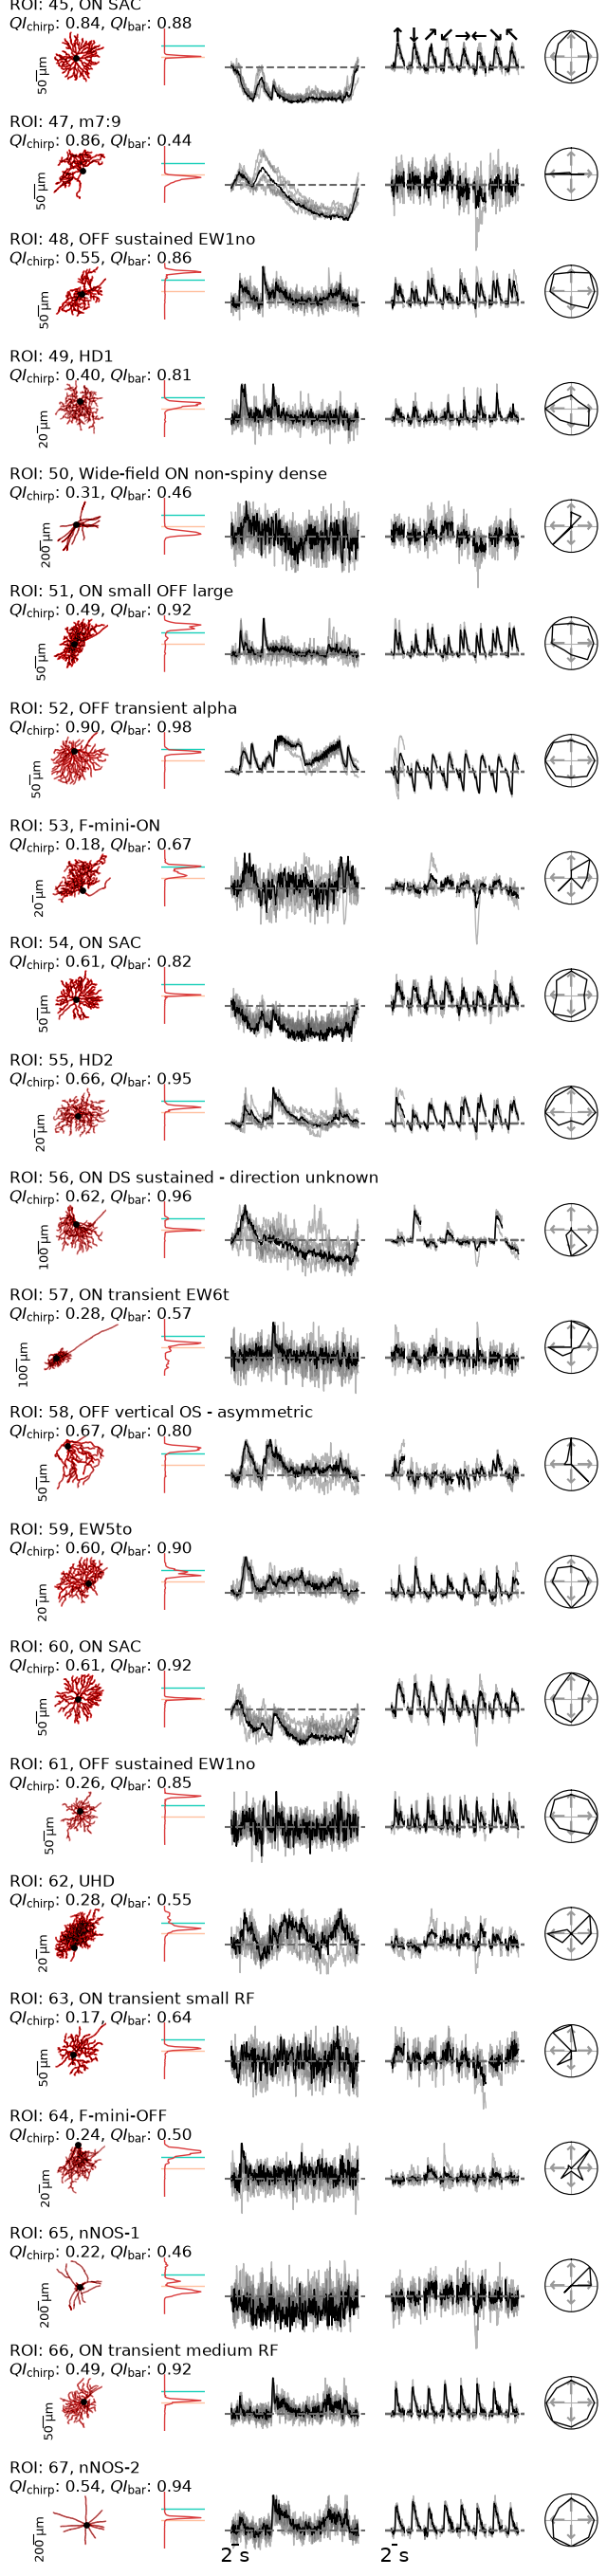

In [55]:
fig, axs = plot_cells(df_func_f3.iloc[44:],
                     figsize=(8, 25),
                     fontsize_factor=1.5)
plt.show()

figname = 'sFig_X_responses_F3_44-66'
fig.patch.set_facecolor('white')
fig.savefig(fig_path +"{}.png".format(figname), bbox_inches='tight', dpi=300, facecolor=fig.get_facecolor(), transparent=False)
fig.savefig(fig_path +"{}.svg".format(figname), bbox_inches='tight', dpi=300, facecolor=fig.get_facecolor(), transparent=False)